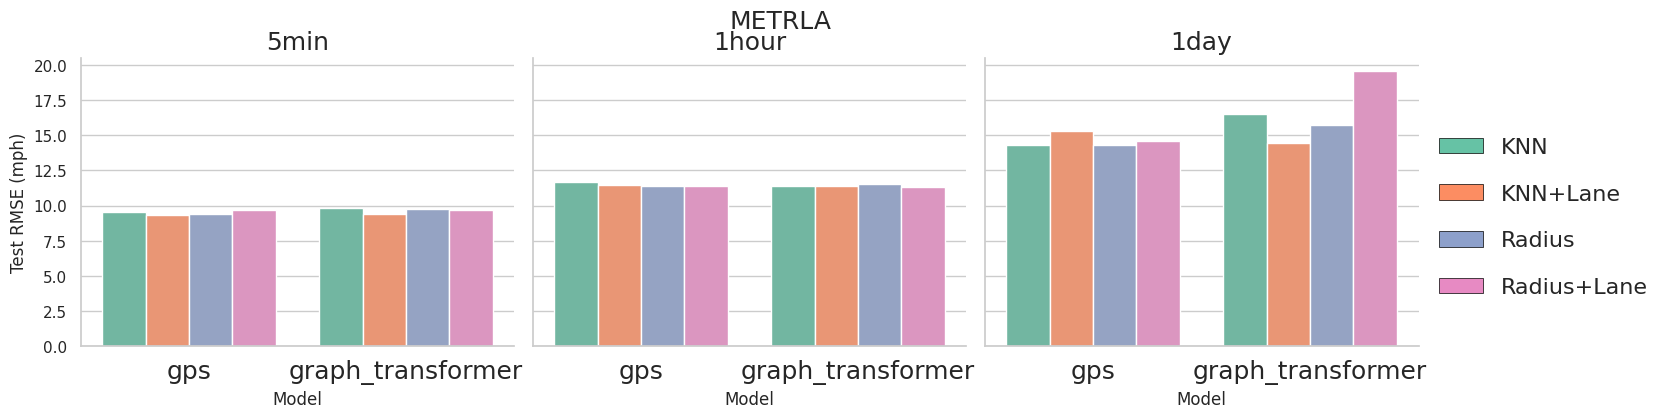

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
import matplotlib as mpl
import matplotlib.cm as cm

# Compatibility patch for matplotlib colormap registration
if not hasattr(cm, 'register_cmap'):
    cm.register_cmap = mpl.colormaps.register

# Mapping from stride to human-readable time frequency
TIMEFREQ_MAP = {1: '5min', 12: '1hour', 288: '1day'}
# Order of models on x-axis
MODEL_ORDER = ['gps', 'graph_transformer']
# Adjacency variants (key in CSV "dataset" column) and display labels
ADJ_VARIANTS = [
    ('adj_mx_knn',          'KNN'),
    ('adj_mx_knn_lane',     'KNN+Lane'),
    ('adj_mx_radius',       'Radius'),
    ('adj_mx_radius_lane',  'Radius+Lane'),
]
PALETTE = sns.color_palette('Set2', n_colors=len(ADJ_VARIANTS))
ADJ_KEYS   = [k for k, _ in ADJ_VARIANTS]
ADJ_LABELS = [l for _, l in ADJ_VARIANTS]

def plot_adj_comparison(df, dataset_type, out_file=None):
    """
    Plot bar charts for a single dataset, faceted by time frequency.
    """
    sns.set(style='whitegrid')

    # Filter only supported adjacency matrix variants
    df = df[df['adj'].isin(ADJ_KEYS)].copy()

    # Map raw adj keys to readable labels
    df['adjacency matrix'] = df['adj'].map(dict(ADJ_VARIANTS))

    # Set categorical order for models and time frequencies
    df['model'] = pd.Categorical(df['model'], categories=MODEL_ORDER, ordered=True)
    df['timefreq'] = pd.Categorical(df['timefreq'], categories=['5min', '1hour', '1day'], ordered=True)

    # Create a bar plot with Seaborn's FacetGrid
    g = sns.catplot(
        data=df,
        x='model', y='rmse_mph',
        hue='adjacency matrix', hue_order=ADJ_LABELS,
        palette=PALETTE,
        col='timefreq',
        kind='bar',
        height=4, aspect=1.2,
    )

    # Set axis labels and subplot titles
    g.set_axis_labels('Model', 'Test RMSE (mph)')
    g.set_titles(col_template='{col_name}', size=18)

    # Remove default legend added by Seaborn
    if g._legend:
        g._legend.remove()

    # Create custom legend handles (color patches)
    handles = [
        Patch(facecolor=color, edgecolor='black', linewidth=0.5, label=label)
        for label, color in zip(ADJ_LABELS, PALETTE)
    ]
    labels = ADJ_LABELS

    # Add a single global legend to the figure
    fig = g.fig
    fig.legend(
        handles, labels,
        title='',
        loc='center left', bbox_to_anchor=(0.9, 0.5),
        frameon=False,
        prop={'size': 16},      # Increase legend font size
        borderaxespad=0.5,
        labelspacing=1.2        # Space between legend entries
    )

    # Increase x-axis tick font size for all subplots
    for ax in g.axes.flatten():
        ax.tick_params(axis='x', labelsize=18)

    # Adjust space for legend
    fig.subplots_adjust(right=0.9)

    # Add a main title for the entire figure
    fig.suptitle(f'{dataset_type.upper()}', y=1.02, size=18)

    # Save figure to file if specified
    if out_file:
        fig.savefig(out_file, dpi=200, bbox_inches='tight')

    # Show the plot
    plt.show()

# Prepare the data for plotting from your provided summary
data = {
    'dataset_type': [],
    'adj': [],
    'model': [],
    'stride': [],
    'timefreq': [],
    'rmse_mph': []
}

# Data for GPS model
gps_results_raw = {
    'adj_mx_knn_lane.pkl': {
        1: {'rmse': 9.3444, 'timefreq': '5min'},
        12: {'rmse': 11.4622, 'timefreq': '1hour'},
        288: {'rmse': 15.3097, 'timefreq': '1day'}
    },
    'adj_mx_knn.pkl': {
        1: {'rmse': 9.5494, 'timefreq': '5min'},
        12: {'rmse': 11.6559, 'timefreq': '1hour'},
        288: {'rmse': 14.2799, 'timefreq': '1day'}
    },
    'adj_mx_radius_lane.pkl': {
        1: {'rmse': 9.6512, 'timefreq': '5min'},
        12: {'rmse': 11.4236, 'timefreq': '1hour'},
        288: {'rmse': 14.5879, 'timefreq': '1day'}
    },
    'adj_mx_radius.pkl': {
        1: {'rmse': 9.4262, 'timefreq': '5min'},
        12: {'rmse': 11.3985, 'timefreq': '1hour'},
        288: {'rmse': 14.2978, 'timefreq': '1day'}
    }
}

# Data for Graph Transformer model
graph_transformer_results_raw = {
    'adj_mx_knn_lane.pkl': {
        1: {'rmse': 9.4333, 'timefreq': '5min'},
        12: {'rmse': 11.3978, 'timefreq': '1hour'},
        288: {'rmse': 14.4177, 'timefreq': '1day'}
    },
    'adj_mx_knn.pkl': {
        1: {'rmse': 9.8425, 'timefreq': '5min'},
        12: {'rmse': 11.3724, 'timefreq': '1hour'},
        288: {'rmse': 16.4938, 'timefreq': '1day'}
    },
    'adj_mx_radius_lane.pkl': {
        1: {'rmse': 9.6791, 'timefreq': '5min'},
        12: {'rmse': 11.2867, 'timefreq': '1hour'},
        288: {'rmse': 19.5445, 'timefreq': '1day'}
    },
    'adj_mx_radius.pkl': {
        1: {'rmse': 9.7784, 'timefreq': '5min'},
        12: {'rmse': 11.5246, 'timefreq': '1hour'},
        288: {'rmse': 15.7469, 'timefreq': '1day'}
    }
}

# Combine all results
all_results = {
    'gps': gps_results_raw,
    'graph_transformer': graph_transformer_results_raw
}

for model_name, results_raw in all_results.items():
    for adj_file_full, strides_data in results_raw.items():
        adj_key = adj_file_full.replace('.pkl', '')
        for stride_val, metrics in strides_data.items():
            data['dataset_type'].append('metrla')
            data['adj'].append(adj_key)
            data['model'].append(model_name)
            data['stride'].append(stride_val)
            data['timefreq'].append(metrics['timefreq'])
            data['rmse_mph'].append(metrics['rmse'])

df_results = pd.DataFrame(data)

# Call the plotting function
output_figure_name = 'metrla_adj_comparison_all_models.png'
plot_adj_comparison(df_results, 'metrla', out_file=output_figure_name)